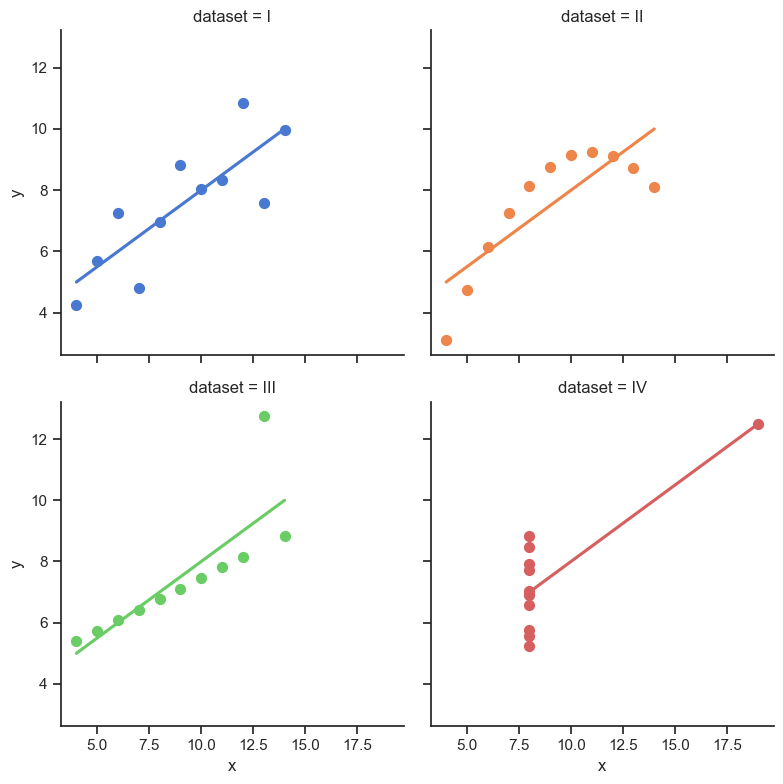

In [1]:
import seaborn as sns
sns.set_theme(style="ticks")

# Load the example dataset for Anscombe's quartet
df = sns.load_dataset("anscombe")

# Show the results of a linear regression within each dataset
sns.lmplot(
    data=df, x="x", y="y", col="dataset", hue="dataset",
    col_wrap=2, palette="muted", ci=None,
    height=4, scatter_kws={"s": 50, "alpha": 1}
)

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

contact = pd.read_csv("vizs2_class_contact_cases.csv",parse_dates=["received_date"])
pump_energy = pd.read_csv("vizs2_class_pump_energy_audits.csv",parse_dates=["inspection_date"])
reservoir_levels = pd.read_csv("vizs2_class_reservoir_reviews.csv",parse_dates=["visit_date"])
treatment = pd.read_csv("vizs2_class_treatment_batches.csv",parse_dates=["batch_date"])
treatment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   batch_id               504 non-null    object        
 1   batch_date             504 non-null    datetime64[ns]
 2   plant                  504 non-null    object        
 3   season                 504 non-null    object        
 4   process                504 non-null    object        
 5   intake_source          504 non-null    object        
 6   raw_turbidity_ntu      504 non-null    float64       
 7   treated_turbidity_ntu  504 non-null    float64       
 8   dose_mg_l              498 non-null    float64       
 9   batch_volume_m3        504 non-null    int64         
 10  energy_kwh             504 non-null    float64       
 11  sample_retests         504 non-null    int64         
 12  operator_shift         504 non-null    object        
dtypes: da

In [38]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
files = ['vizs2_class_contact_cases.csv',
'vizs2_class_treatment_batches.csv',
'vizs2_class_pump_energy_audits.csv']
cases, treat, pumps = [pd.read_csv(f) for f in files]
print(len(cases), len(treat), len(pumps))

624 504 420


In [10]:
files

['vizs2_class_contact_cases.csv',
 'vizs2_class_treatment_batches.csv',
 'vizs2_class_pump_energy_audits.csv']

In [26]:
cols = ['service_channel',
'response_hours', 'priority']
print(cases[cols].dtypes)
print('rows:', len(cases))
print('missing:',cases.response_hours.isna().sum())


service_channel     object
response_hours     float64
priority            object
dtype: object
rows: 624
missing: 7


In [15]:
sns.load_dataset('tips')

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [17]:
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

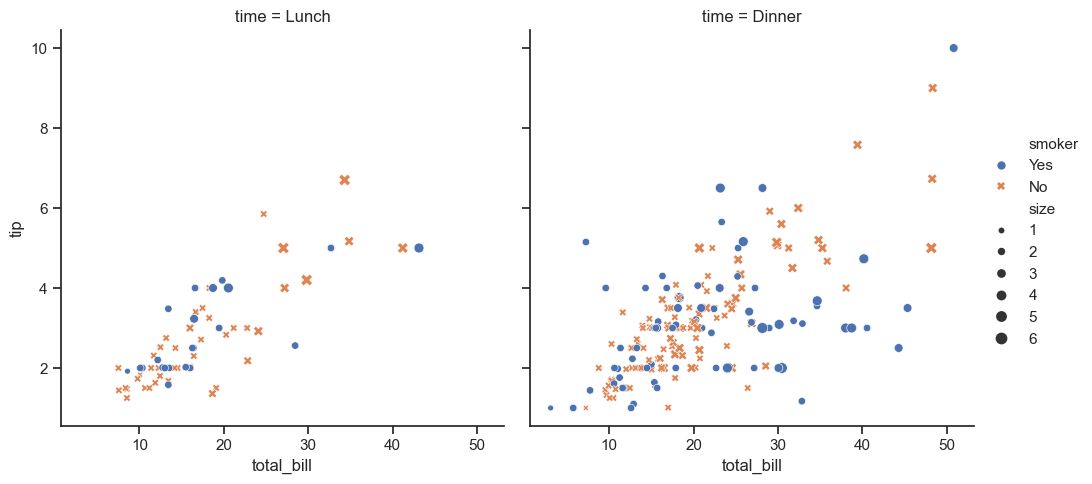

In [24]:
tips_data = sns.load_dataset("tips")
sns.relplot(data=tips_data, x="total_bill", y="tip", col="time", hue="smoker", style="smoker", size="size")

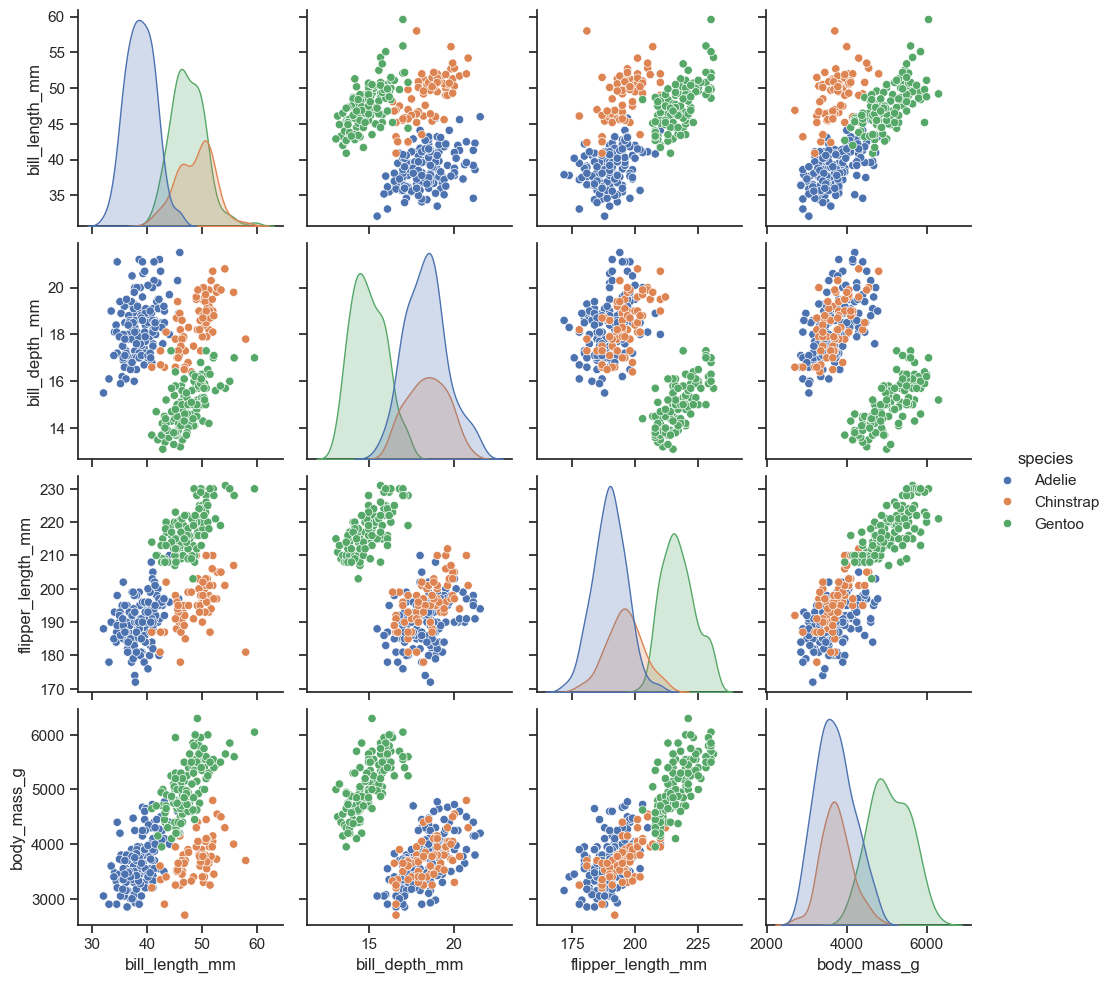

In [25]:
import seaborn as sns
df = sns.load_dataset("penguins")
sns.pairplot(df, hue="species")

Figure
Axes


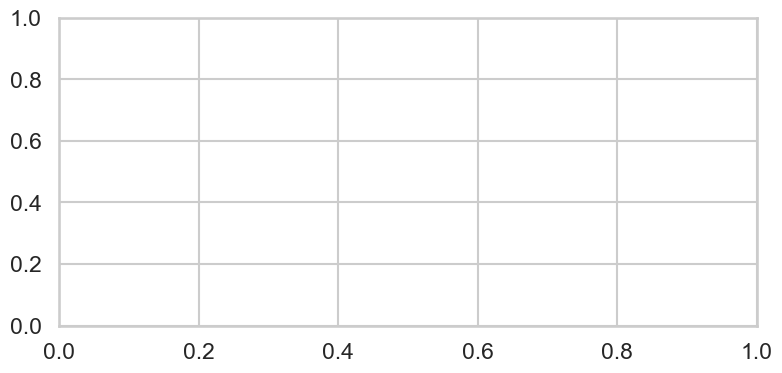

In [29]:
sns.set_theme(style='whitegrid',
context='talk',
palette='colorblind')
fig, ax = plt.subplots(figsize=(9, 4))
print(type(fig).__name__)
print(type(ax).__name__)

<Axes: ylabel='total_bill'>

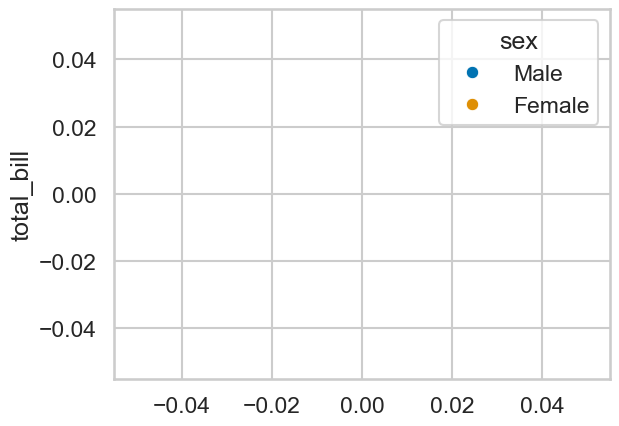

In [36]:
sns.scatterplot(data=tips_data, y="total_bill", hue="sex")

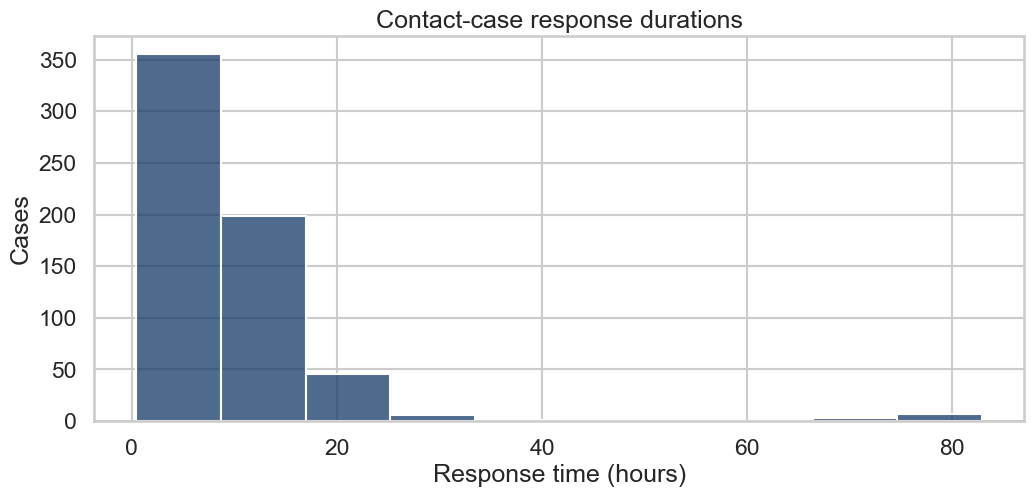

In [43]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(data=cases, x='response_hours',
            bins=10, color='#123867', ax=ax)
ax.set(title='Contact-case response durations',
       xlabel='Response time (hours)',
       ylabel='Cases')
plt.show()

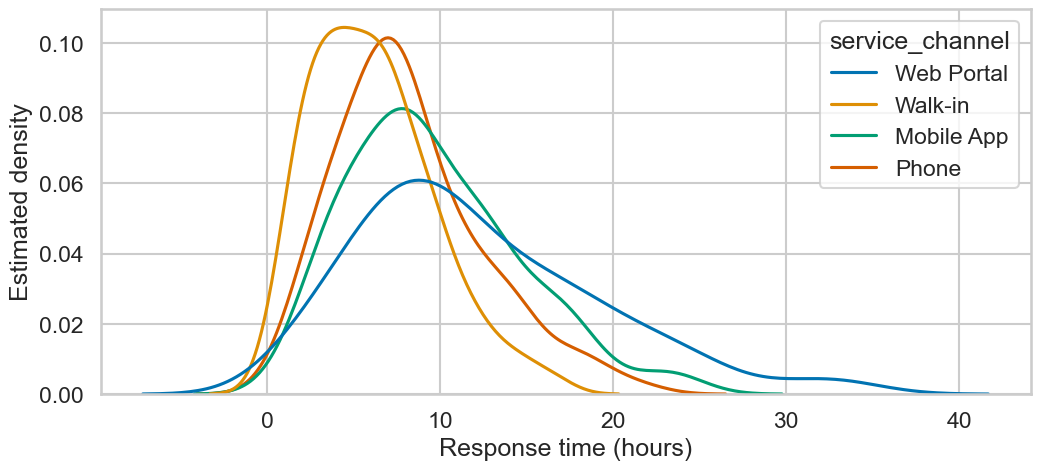

In [48]:
subset = cases.query('response_hours <=60')
fig, ax = plt.subplots(figsize=(12, 5))
sns.kdeplot(data=subset,
            x='response_hours',
            hue='service_channel',
            common_norm=False, ax=ax)
ax.set(xlabel='Response time (hours)',
       ylabel='Estimated density')
plt.show()

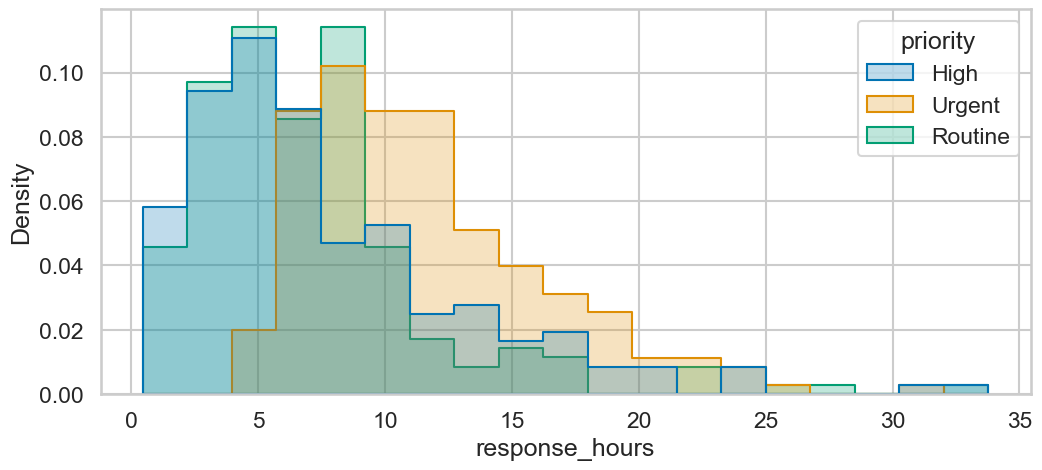

In [49]:
subset = cases.query('response_hours <= 60')
fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(data=subset,
x='response_hours', hue='priority',
stat='density', common_norm=False,
element='step', bins=19, ax=ax)
plt.show()

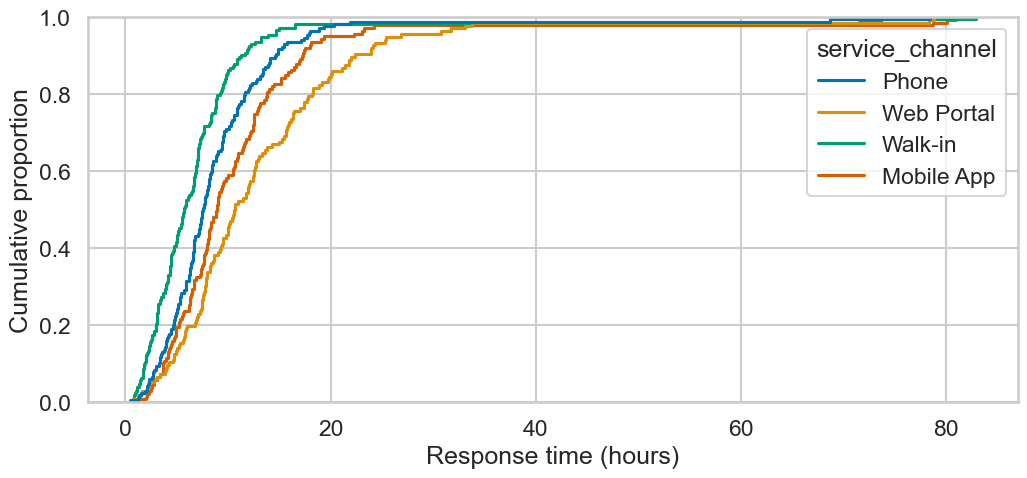

In [50]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.ecdfplot(data=cases,
             x='response_hours',
             hue='service_channel', ax=ax)
ax.set(xlabel='Response time (hours)',
       ylabel='Cumulative proportion')
plt.show()

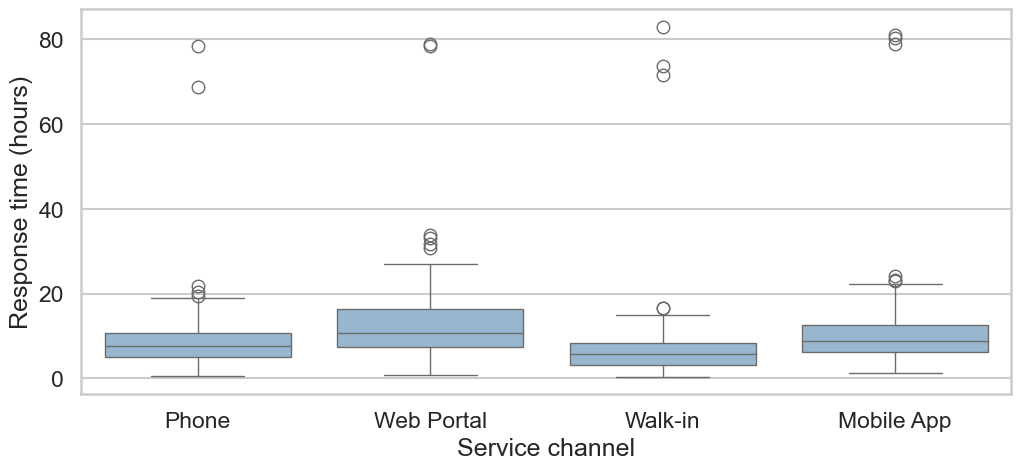

In [51]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=cases,
x='service_channel',
y='response_hours',
color='#8FB9D7', ax=ax)
ax.set(xlabel='Service channel',
ylabel='Response time (hours)')
plt.show()

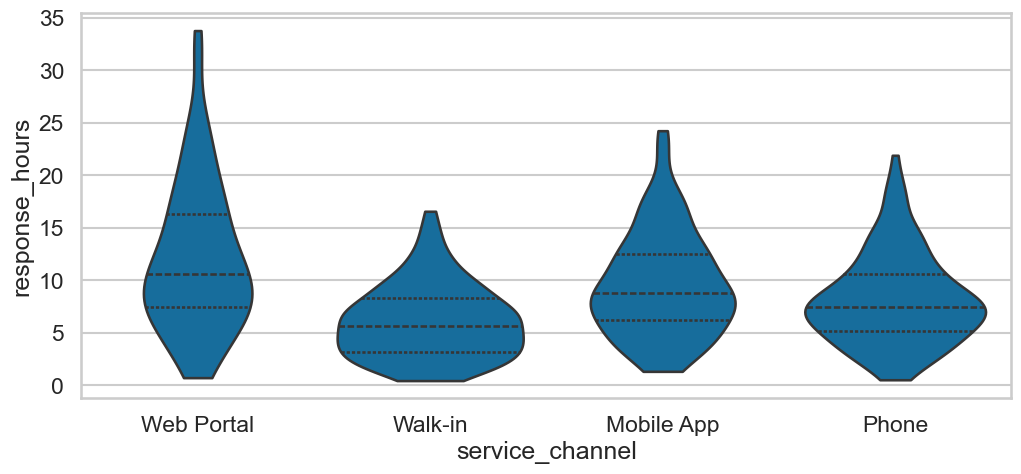

In [52]:
subset = cases.query('response_hours <= 60')
fig, ax = plt.subplots(figsize=(12, 5))
sns.violinplot(data=subset,
x='service_channel',
y='response_hours',
inner='quart', cut=0, ax=ax)
plt.show()

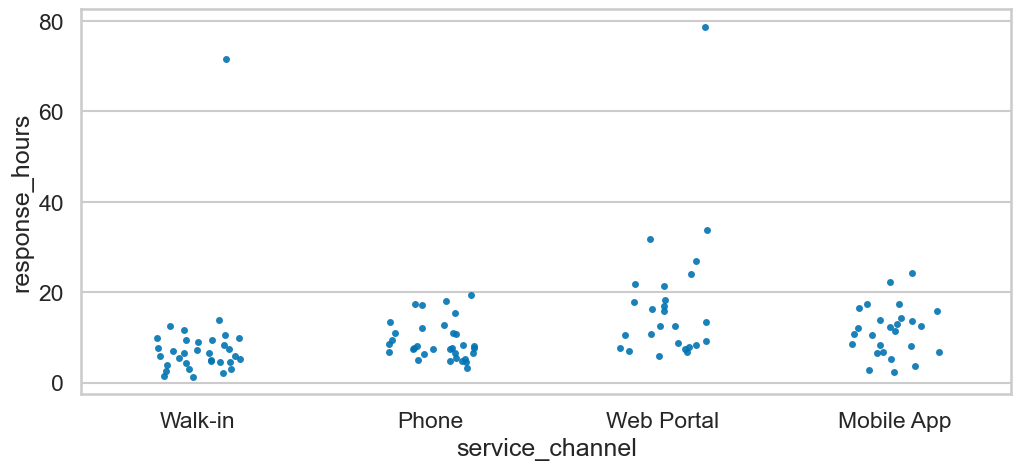

In [59]:
sample = cases.sample(120, random_state=7)
fig, ax = plt.subplots(figsize=(12, 5))
sns.stripplot(data=sample,
x='service_channel',
y='response_hours',
jitter=.19, alpha=.90, ax=ax)
plt.show()

In [60]:
q1, q3 = cases.response_hours.quantile(
    [.25, .75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
flagged = cases.response_hours.gt(upper)
print(round(upper, 2))
print(int(flagged.sum()))

22.28
26


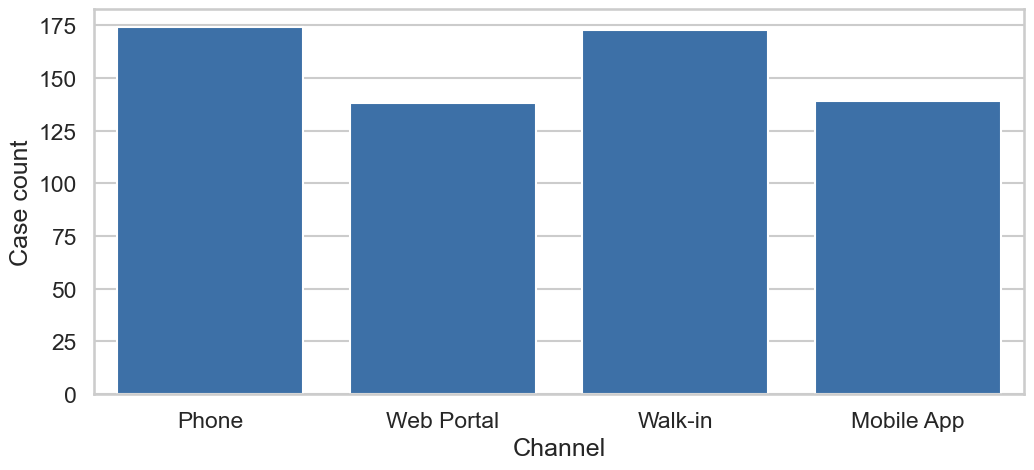

In [70]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.countplot(data=cases,
              x='service_channel',
              color='#2C70B8', ax=ax)
ax.set(xlabel='Channel', ylabel='Case count')
plt.show()

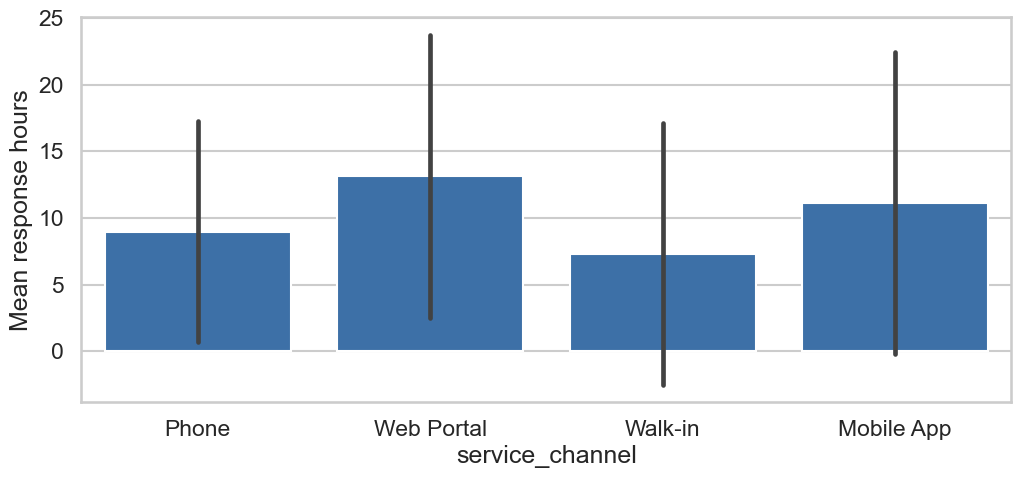

In [72]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=cases,
x='service_channel',
y='response_hours',
estimator='mean',
errorbar='sd', color='#2C70B8',
ax=ax)
ax.set(ylabel='Mean response hours')
plt.show()

In [73]:
print(cases.groupby('service_channel')
.response_hours.mean().round(1))

service_channel
Mobile App    11.1
Phone          9.0
Walk-in        7.3
Web Portal    13.1
Name: response_hours, dtype: float64


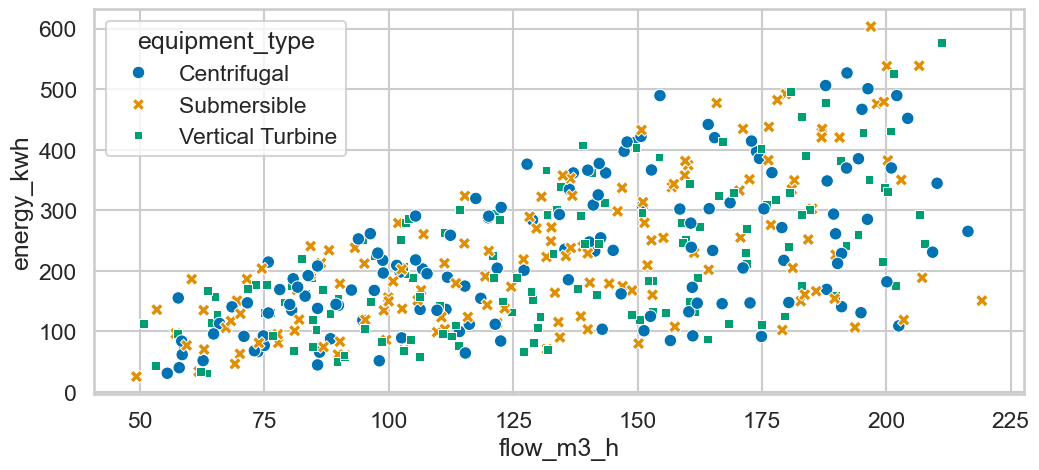

In [74]:
ig, ax = plt.subplots(figsize=(12, 5))
sns.scatterplot(
data=pumps,
x='flow_m3_h',
y='energy_kwh',
hue='equipment_type',
style='equipment_type',
ax=ax
)
plt.show()

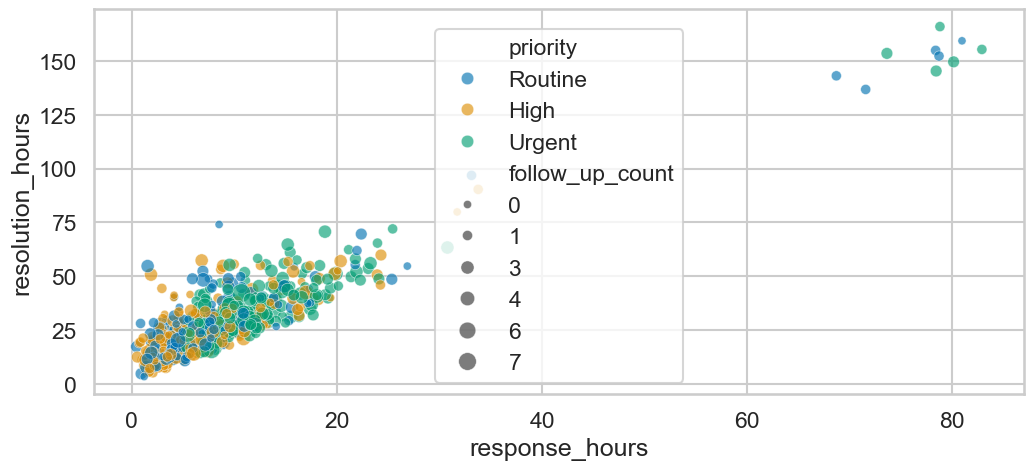

In [75]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.scatterplot(
data=cases,
x='response_hours', y='resolution_hours',
hue='priority', size='follow_up_count',
sizes=(35, 180), alpha=.64, ax=ax
)
plt.show()

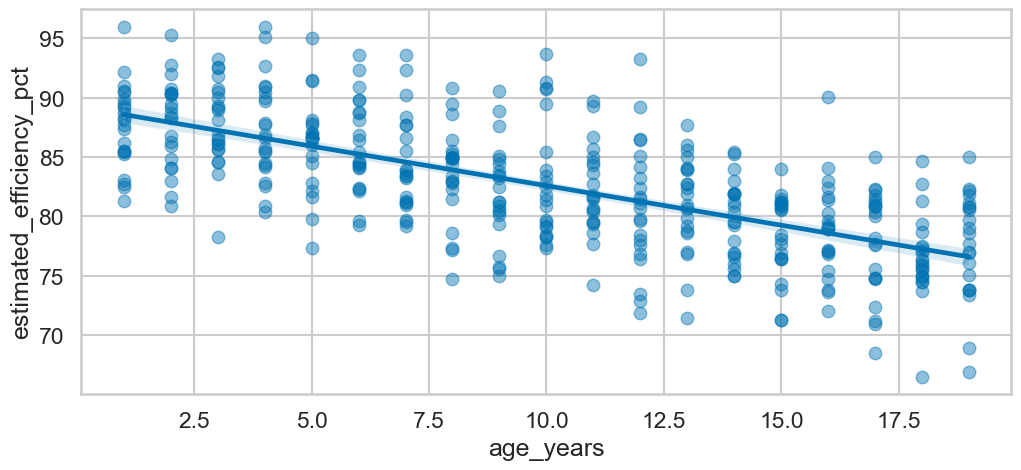

In [76]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.regplot(
data=pumps,
x='age_years',
y='estimated_efficiency_pct',
scatter_kws={'alpha': .45},
ax=ax
)
plt.show()

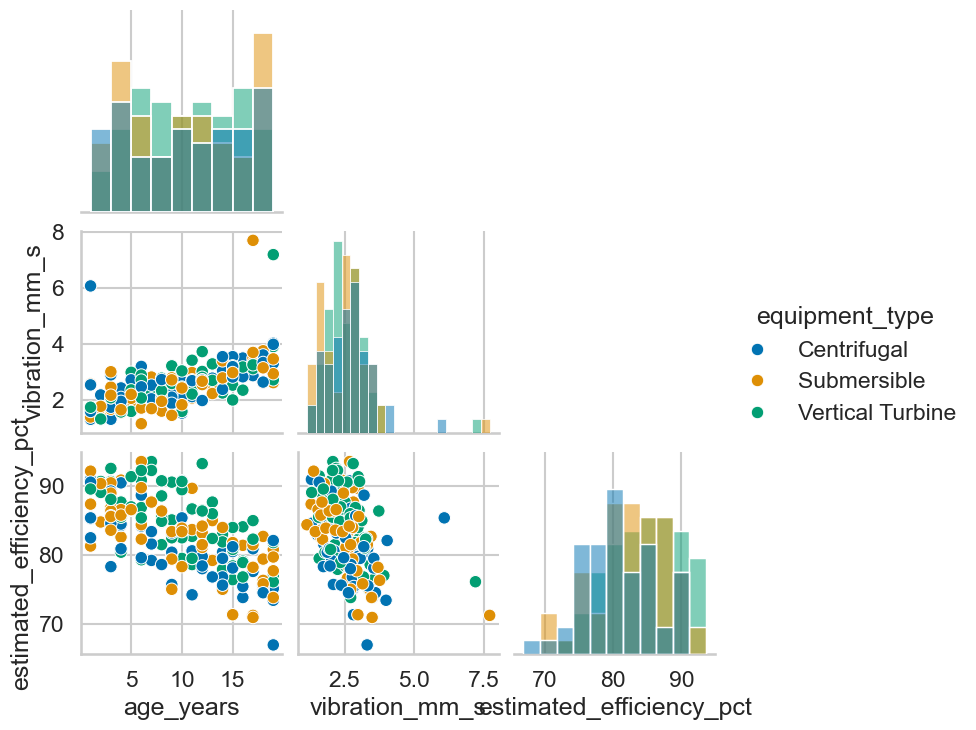

In [77]:
subset = pumps[[
'age_years', 'vibration_mm_s',
'estimated_efficiency_pct',
'equipment_type']].sample(180, random_state=6)
g = sns.pairplot(subset,
hue='equipment_type', corner=True,
diag_kind='hist')
plt.show()

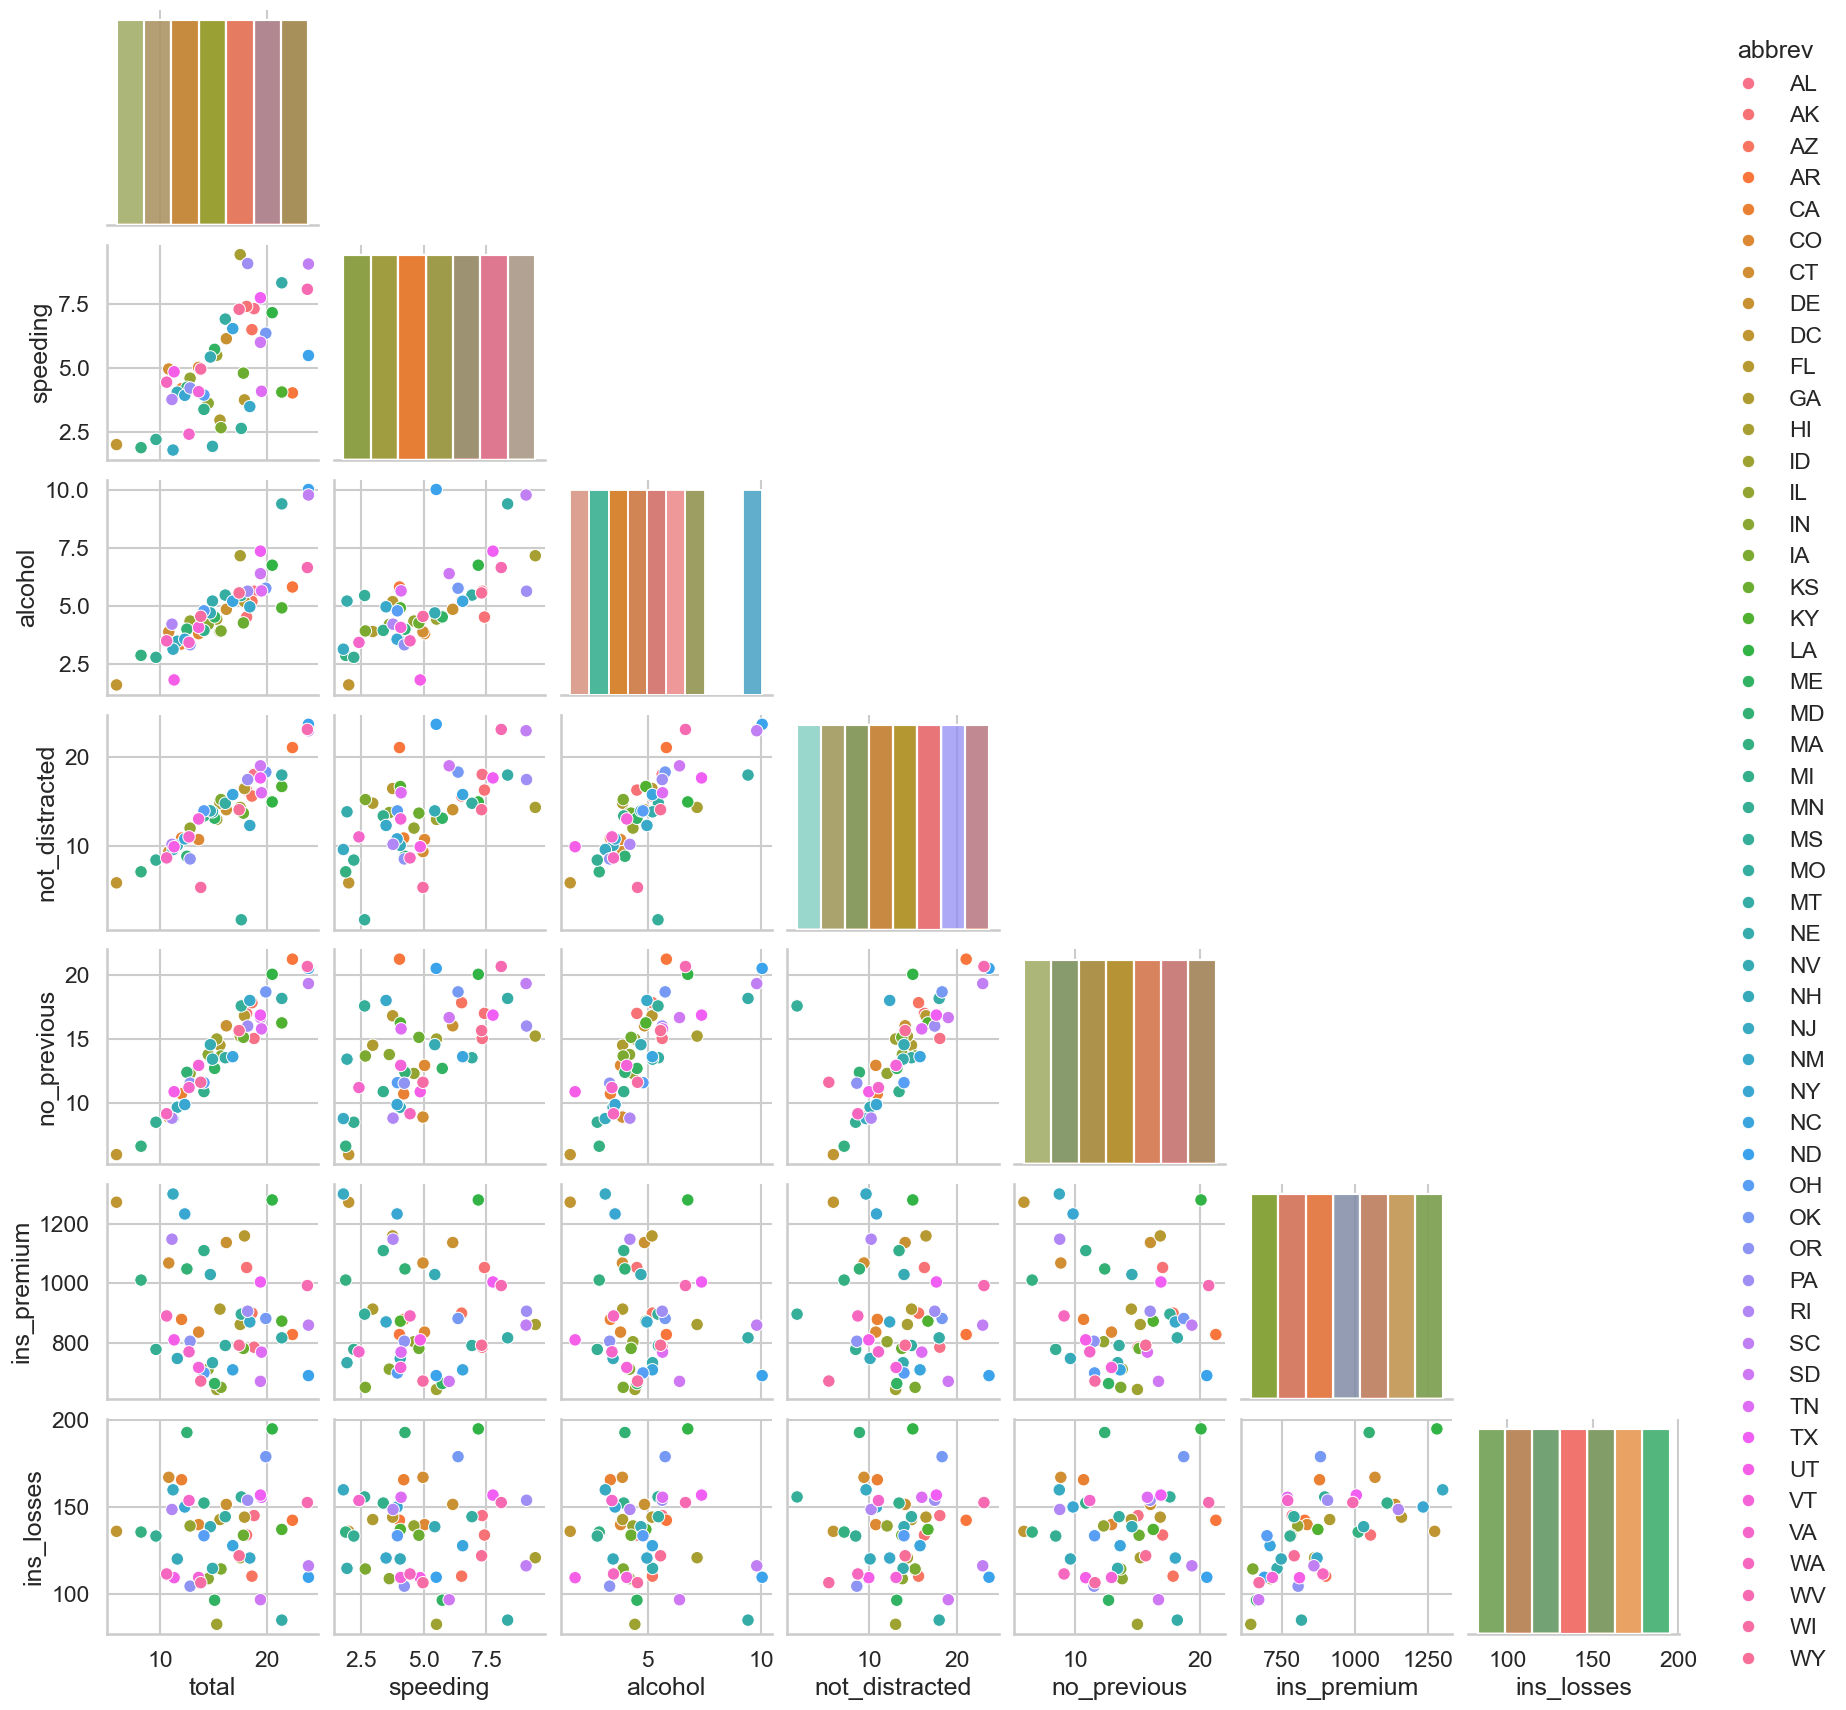

In [88]:
sns.get_dataset_names()

sns.load_dataset('car_crashes')
subset_car_crashes = sns.load_dataset('car_crashes')
f = sns.pairplot(subset_car_crashes, hue='abbrev', corner=True, diag_kind='hist')
plt.show()

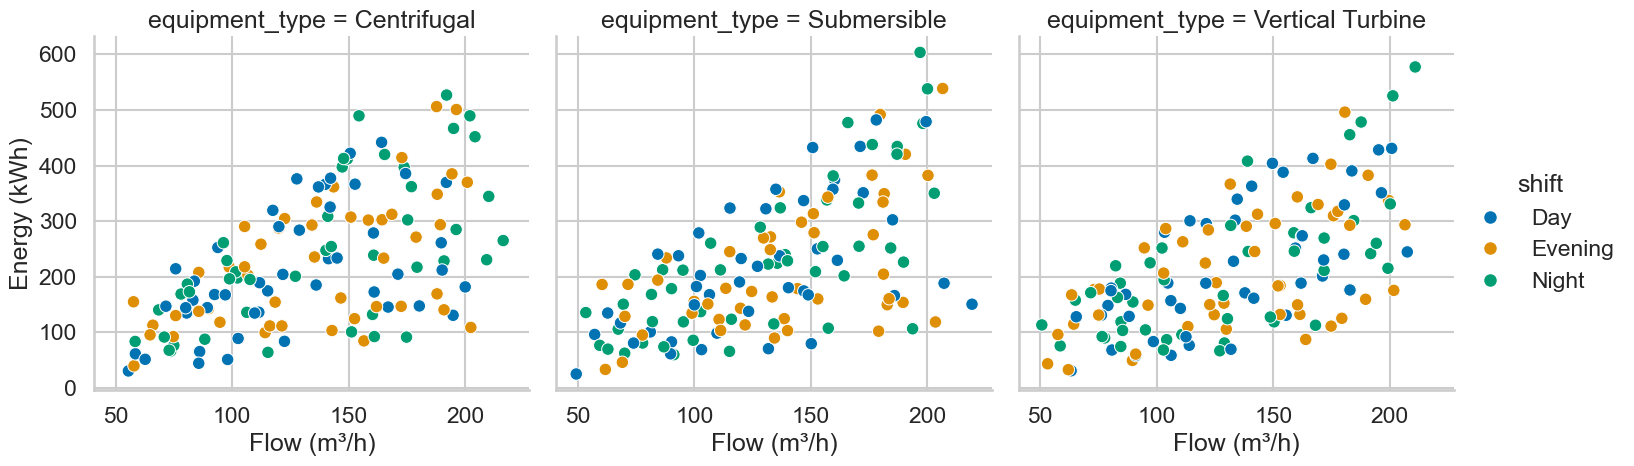

In [89]:
g = sns.relplot(data=pumps,
x='flow_m3_h', y='energy_kwh',
col='equipment_type', hue='shift',
kind='scatter', col_wrap=3)
g.set_axis_labels('Flow (m³/h)',
'Energy (kWh)')
plt.show()

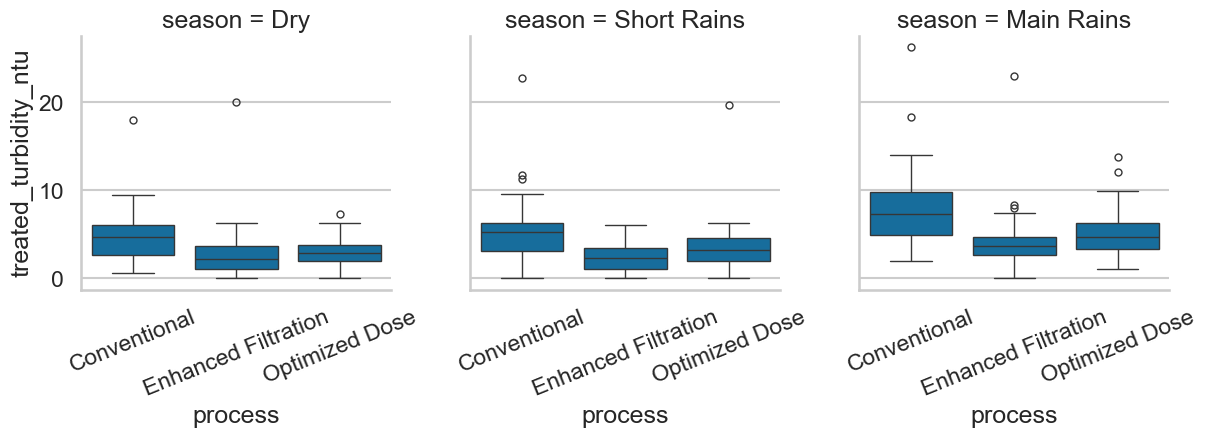

In [90]:
g = sns.catplot(data=treat,
x='process', y='treated_turbidity_ntu',
col='season', kind='box',
col_wrap=3, height=4)
g.set_xticklabels(rotation=22)
plt.show()

-0.675


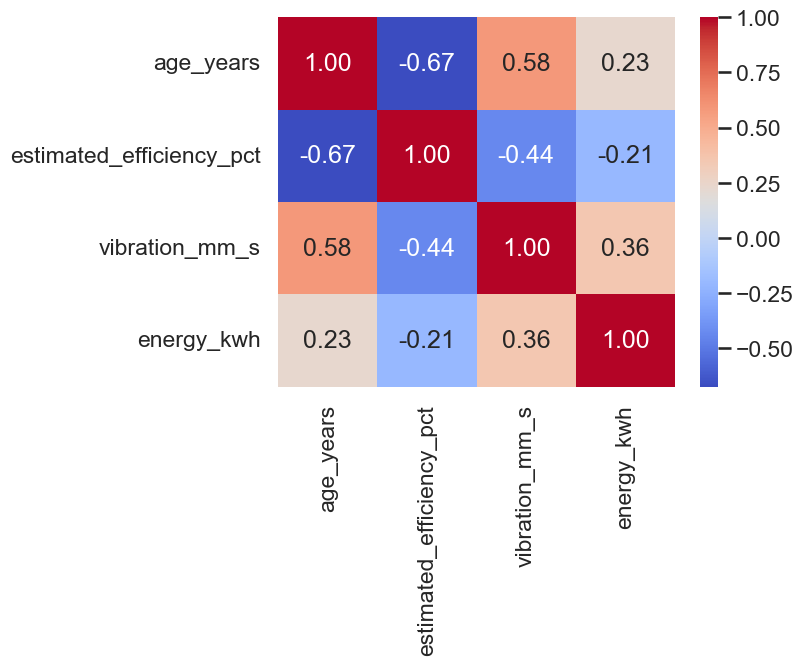

In [93]:
corr = pumps[[
'age_years',
'estimated_efficiency_pct',
'vibration_mm_s', 'energy_kwh'
]].corr()
print(round(corr.loc[
'age_years',
'estimated_efficiency_pct'
], 3))
b = sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')